In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')

PLOTS_DIR = "../static/plots"
os.makedirs(PLOTS_DIR, exist_ok=True)

In [6]:

model_files = [
    '../data/logistic_regression_results.csv',
    '../data/random_forest_results.csv', 
    '../data/xgboost_results.csv',
    '../data/svm_results.csv',
    '../data/mlp_results.csv'
]

model_names = [
    'Regresja Logistyczna',
    'Random Forest',
    'XGBoost', 
    'SVM',
    'MLP'
]

all_results = []

for file_path, name in zip(model_files, model_names):
    try:
        df = pd.read_csv(file_path)
        df['Model'] = name
        all_results.append(df)
        print(f"Wczytano wyniki dla: {name}")
    except FileNotFoundError:
        print(f"Nie znaleziono pliku: {file_path}")

if all_results:
    results_df = pd.concat(all_results, ignore_index=True)
    print(f"\nPorównanie {len(all_results)} modeli:")
    print(results_df.head())
else:
    print("Nie znaleziono żadnych wyników modeli!")

Wczytano wyniki dla: Regresja Logistyczna
Wczytano wyniki dla: Random Forest
Wczytano wyniki dla: XGBoost
Wczytano wyniki dla: SVM
Wczytano wyniki dla: MLP

Porównanie 5 modeli:
      Metryka   Wartość                 Model
0  Dokładność  0.999936  Regresja Logistyczna
1    Precyzja  0.999926  Regresja Logistyczna
2     Czułość  0.999963  Regresja Logistyczna
3    Miara F1  0.999944  Regresja Logistyczna
4     AUC-ROC  1.000000  Regresja Logistyczna


In [7]:

if all_results:
    comparison_table = results_df.pivot(index='Metryka', columns='Model', values='Wartość')
    
    print("TABELA PORÓWNAWCZA WSZYSTKICH MODELI")
    print("=" * 60)
    print(comparison_table.round(4))
    
    print("\nNAJLEPSZE WYNIKI:")
    print("=" * 40)
    for metric in comparison_table.index:
        best_model = comparison_table.loc[metric].idxmax()
        best_score = comparison_table.loc[metric].max()
        print(f"{metric}: {best_model} ({best_score:.4f})")
    
    print("\nOCENA WZGLĘDEM CELU 95%:")
    print("=" * 40)
    goal_achievement = comparison_table >= 0.95
    for model in comparison_table.columns:
        achieved = goal_achievement[model].sum()
        total = len(goal_achievement[model])
        status = "OSIĄGNIĘTY" if achieved == total else f"{achieved}/{total}"
        print(f"{model}: {status}")

TABELA PORÓWNAWCZA WSZYSTKICH MODELI
Model          MLP  Random Forest  Regresja Logistyczna     SVM  XGBoost
Metryka                                                                 
AUC-ROC     1.0000            1.0                1.0000  1.0000      1.0
Czułość     1.0000            1.0                1.0000  1.0000      1.0
Dokładność  1.0000            1.0                0.9999  1.0000      1.0
Miara F1    1.0000            1.0                0.9999  1.0000      1.0
Precyzja    0.9999            1.0                0.9999  0.9999      1.0

NAJLEPSZE WYNIKI:
AUC-ROC: Random Forest (1.0000)
Czułość: MLP (1.0000)
Dokładność: XGBoost (1.0000)
Miara F1: XGBoost (1.0000)
Precyzja: XGBoost (1.0000)

OCENA WZGLĘDEM CELU 95%:
MLP: OSIĄGNIĘTY
Random Forest: OSIĄGNIĘTY
Regresja Logistyczna: OSIĄGNIĘTY
SVM: OSIĄGNIĘTY
XGBoost: OSIĄGNIĘTY


Wykres porównawczy zapisany jako: ../static/plots/comprehensive_model_comparison.png


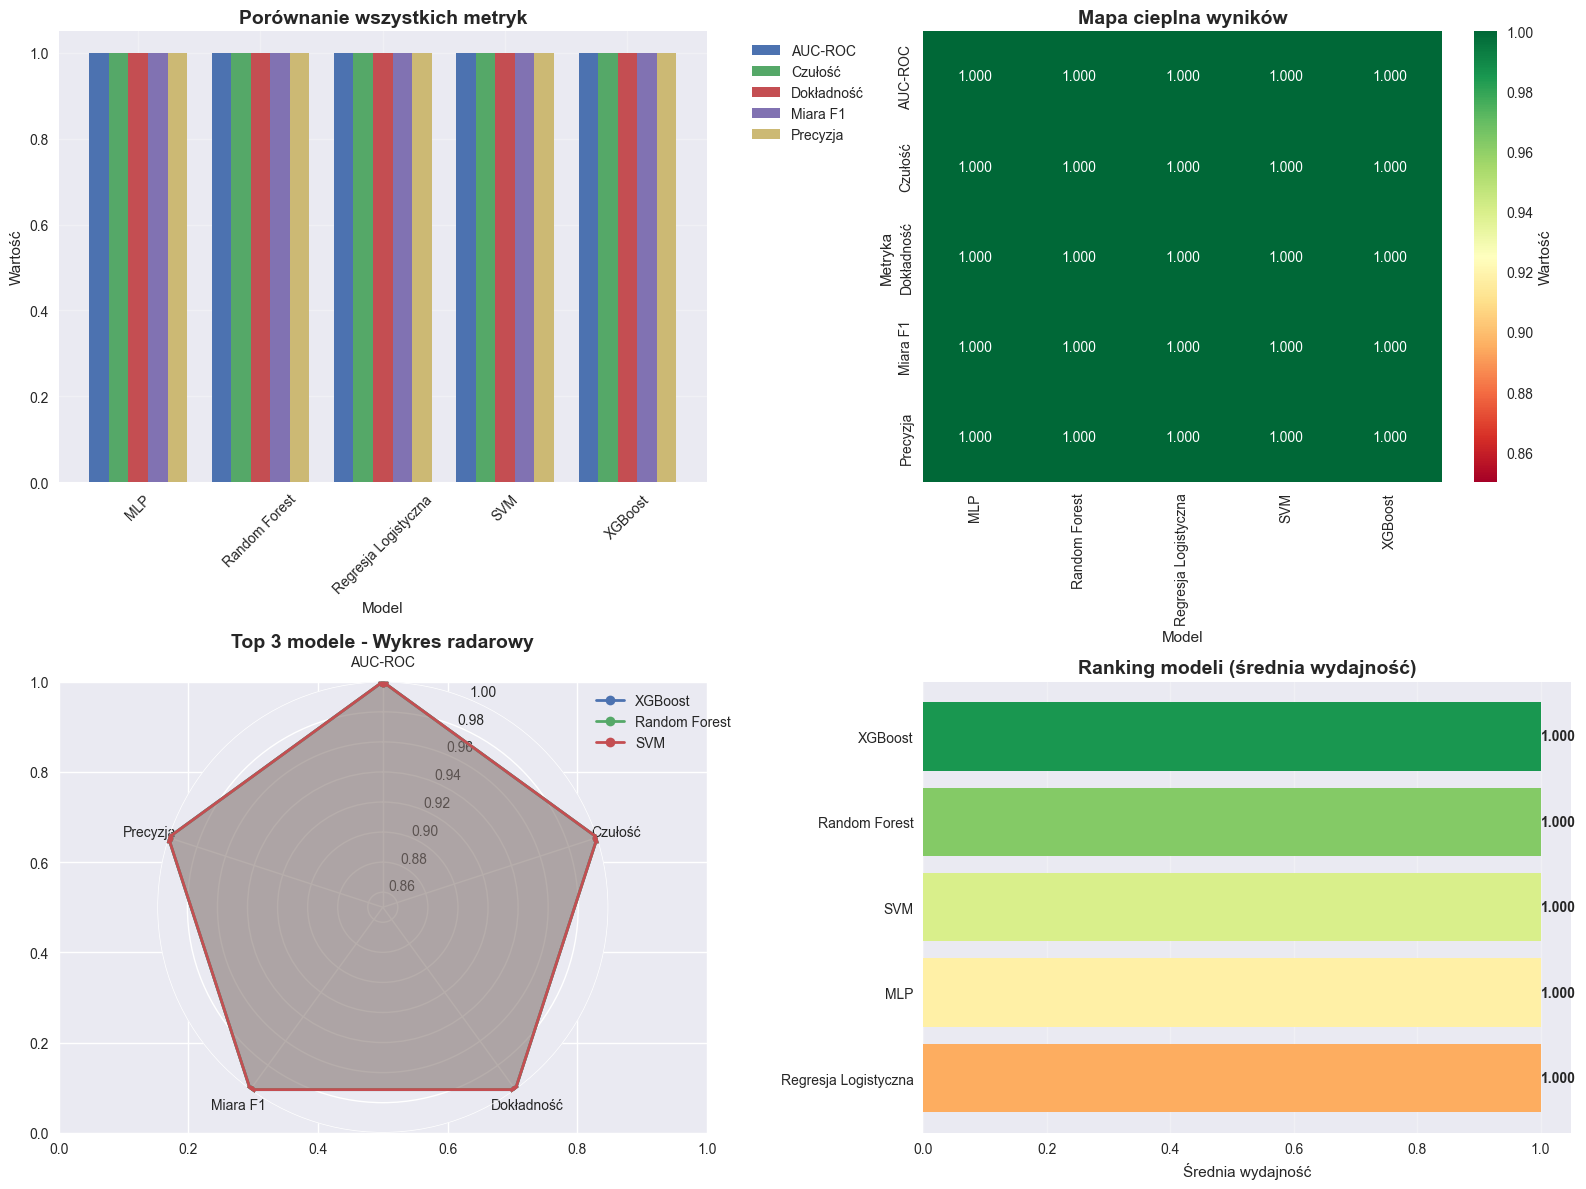

In [8]:
if all_results:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    comparison_table.T.plot(kind='bar', ax=axes[0,0], width=0.8)
    axes[0,0].set_title('Porównanie wszystkich metryk', fontsize=14, fontweight='bold')
    axes[0,0].set_ylabel('Wartość')
    axes[0,0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[0,0].tick_params(axis='x', rotation=45)
    axes[0,0].grid(True, alpha=0.3)
    
    sns.heatmap(comparison_table, annot=True, fmt='.3f', cmap='RdYlGn', 
                vmin=0.85, vmax=1.0, ax=axes[0,1], cbar_kws={'phishing': 'Wartość'})
    axes[0,1].set_title('Mapa cieplna wyników', fontsize=14, fontweight='bold')
    
    from math import pi
    
    avg_performance = comparison_table.mean(axis=0).sort_values(ascending=False)
    top_models = avg_performance.head(3).index.tolist()
    
    metrics = comparison_table.index.tolist()
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  
    
    ax = fig.add_subplot(2, 2, 3, projection='polar')
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    
    for model in top_models:
        values = comparison_table[model].tolist()
        values += values[:1] 
        ax.plot(angles, values, 'o-', linewidth=2, label=model)
        ax.fill(angles, values, alpha=0.25)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics)
    ax.set_ylim(0.85, 1.0)
    ax.set_title('Top 3 modele - Wykres radarowy', fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
    ax.grid(True)
    
    ranking = avg_performance.sort_values(ascending=True)
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(ranking)))
    bars = axes[1,1].barh(range(len(ranking)), ranking.values, color=colors)
    axes[1,1].set_yticks(range(len(ranking)))
    axes[1,1].set_yticklabels(ranking.index)
    axes[1,1].set_xlabel('Średnia wydajność')
    axes[1,1].set_title('Ranking modeli (średnia wydajność)', fontsize=14, fontweight='bold')
    axes[1,1].grid(True, alpha=0.3)
    
    for i, bar in enumerate(bars):
        width = bar.get_width()
        axes[1,1].text(width + 0.001, bar.get_y() + bar.get_height()/2, 
                      f'{width:.3f}', ha='left', va='center', fontweight='bold')
    
    plt.tight_layout()
    
    comparison_plot_filename = f"{PLOTS_DIR}/comprehensive_model_comparison.png"
    plt.savefig(comparison_plot_filename, dpi=300, bbox_inches='tight')
    print(f"Wykres porównawczy zapisany jako: {comparison_plot_filename}")
    
    plt.show()

In [9]:
if all_results:
    print("PODSUMOWANIE KOŃCOWE")
    print("=" * 60)
    
    best_overall = avg_performance.idxmax()
    best_score = avg_performance.max()
    
    print(f"NAJLEPSZY MODEL: {best_overall}")
    print(f"Średnia wydajność: {best_score:.4f}")
    
    print(f"\nNAJLEPSZE WYNIKI W POSZCZEGÓLNYCH METRYKACH:")
    for metric in comparison_table.index:
        best_model = comparison_table.loc[metric].idxmax()
        best_value = comparison_table.loc[metric].max()
        print(f"   {metric}: {best_model} ({best_value:.4f})")
    
    print(f"\n MODELE OSIĄGAJĄCE CEL 95% DLA WSZYSTKICH METRYK:")
    goal_models = []
    for model in comparison_table.columns:
        if (comparison_table[model] >= 0.95).all():
            goal_models.append(model)
            print(f"    {model}")
    
    if not goal_models:
        print("Żaden model nie osiągnął celu 95% dla wszystkich metryk")
    
    print(f"\nREKOMENDACJE:")
    print(f"   Dla najwyższej dokładności: {comparison_table.loc['Dokładność'].idxmax()}")
    print(f"   Dla najlepszej precyzji: {comparison_table.loc['Precyzja'].idxmax()}")
    print(f"   Dla najwyższej czułości: {comparison_table.loc['Czułość'].idxmax()}")
    print(f"   Dla najlepszej miary F1: {comparison_table.loc['Miara F1'].idxmax()}")
    print(f"   Dla najwyższego AUC-ROC: {comparison_table.loc['AUC-ROC'].idxmax()}")
    
    comparison_table.to_csv('../data/comprehensive_model_comparison.csv')

PODSUMOWANIE KOŃCOWE
NAJLEPSZY MODEL: XGBoost
Średnia wydajność: 1.0000

NAJLEPSZE WYNIKI W POSZCZEGÓLNYCH METRYKACH:
   AUC-ROC: Random Forest (1.0000)
   Czułość: MLP (1.0000)
   Dokładność: XGBoost (1.0000)
   Miara F1: XGBoost (1.0000)
   Precyzja: XGBoost (1.0000)

 MODELE OSIĄGAJĄCE CEL 95% DLA WSZYSTKICH METRYK:
    MLP
    Random Forest
    Regresja Logistyczna
    SVM
    XGBoost

REKOMENDACJE:
   Dla najwyższej dokładności: XGBoost
   Dla najlepszej precyzji: XGBoost
   Dla najwyższej czułości: MLP
   Dla najlepszej miary F1: XGBoost
   Dla najwyższego AUC-ROC: Random Forest
